# 00 — Phạm vi và môi trường

Dự báo doanh số theo ngày, cửa hàng và mặt hàng. Notebook ghi lại phạm vi dữ liệu, cách chấm điểm và giới hạn của máy.


## 1. Bài toán

Dự báo `unit_sales` cho từng cặp cửa hàng–mặt hàng trong 16 ngày tiếp theo.


In [1]:
PROJECT_NAME = "Machine Learning Final Project"
DATA_DIR = "../data"
RAW_DATA_DIR = "../data/raw"

TARGET_COLUMN = "unit_sales"

TASK_TYPE = "Time Series Forecasting"

print(f"Project: {PROJECT_NAME}")
print(f"Task: {TASK_TYPE}")
print(f"Target: {TARGET_COLUMN}")
print(f"Raw data directory: {RAW_DATA_DIR}")

Project: Machine Learning Final Project
Task: Time Series Forecasting
Target: unit_sales
Raw data directory: ../data/raw


Dữ liệu gốc nằm trong `data/raw/`. Các bước sau đọc dữ liệu này và lưu kết quả riêng.


## 2. Khoảng dự báo

| Nội dung | Giá trị |
|---|---|
| Đơn vị dự báo | `(date, store_nbr, item_nbr)` |
| Target | `unit_sales` |
| Ngày cuối lịch sử | 15/08/2017 |
| Khoảng dự báo | 16–31/08/2017 |
| Đầu ra | `id`, `unit_sales` theo mẫu nộp bài |

Cell dưới kiểm tra khoảng ngày và số cặp trong test.


In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

RAW_DATA_DIR = Path("../data/raw")

test_keys = pd.read_csv(
    RAW_DATA_DIR / "test.csv",
    usecols=["date", "store_nbr", "item_nbr"],
    dtype={"date": "string", "store_nbr": "int16", "item_nbr": "int32"},
)
test_dates = pd.to_datetime(test_keys["date"])

FORECAST_START = test_dates.min()
FORECAST_END = test_dates.max()
FORECAST_HORIZON_DAYS = int(test_dates.nunique())
EXPECTED_TRAIN_END = FORECAST_START - pd.Timedelta(days=1)

n_pairs_test = len(test_keys[["store_nbr", "item_nbr"]].drop_duplicates())
is_full_grid = (n_pairs_test * FORECAST_HORIZON_DAYS) == len(test_keys)
is_contiguous = (FORECAST_END - FORECAST_START).days + 1 == FORECAST_HORIZON_DAYS

horizon_summary = pd.Series({
    "forecast_start": FORECAST_START.date(),
    "forecast_end": FORECAST_END.date(),
    "horizon_days": FORECAST_HORIZON_DAYS,
    "expected_train_end (start - 1 day)": EXPECTED_TRAIN_END.date(),
    "test_rows": len(test_keys),
    "unique_store_item_pairs": n_pairs_test,
    "test_is_full_pair_x_day_grid": is_full_grid,
    "test_dates_contiguous": is_contiguous,
    "unique_stores": test_keys["store_nbr"].nunique(),
    "unique_items": test_keys["item_nbr"].nunique(),
})
display(horizon_summary.to_frame("value"))

del test_keys, test_dates

,value
forecast_start,2017-08-16
forecast_end,2017-08-31
horizon_days,16
expected_train_end (start - 1 day),2017-08-15
test_rows,3370464
unique_store_item_pairs,210654
test_is_full_pair_x_day_grid,True
test_dates_contiguous,True
unique_stores,54
unique_items,3901


Test có **3.370.464 dòng**, bằng 210.654 cặp × 16 ngày. Train không có dòng doanh số bằng 0. Ngày không có dòng có thể là không bán hoặc không niêm yết; cần phân biệt với giai đoạn cửa hàng chưa hoạt động.

Validation cũng dùng cửa sổ 16 ngày để gần với cách dự báo test.


## 3. Thước đo sai số

Dự án dùng NWRMSLE, với trọng số 1,25 cho hàng mau hỏng và 1 cho hàng còn lại:

$$
\mathrm{NWRMSLE}=\sqrt{\frac{\sum_i w_i[\ln(1+\hat y_i)-\ln(1+y_i)]^2}{\sum_i w_i}}
$$

Target và dự báo âm được cắt về 0 khi tính điểm. Target học là `log1p(clip(unit_sales, 0))`. Cần đối chiếu metric với yêu cầu môn học.

Bộ kiểm tra dưới có **một trường hợp cố tình sai** (`== 999.0`). Dòng FAIL này kiểm tra việc phát hiện lỗi, không phải lỗi của công thức metric.


In [3]:
PERISHABLE_WEIGHT = 1.25
NON_PERISHABLE_WEIGHT = 1.00


def nwrmsle(y_true, y_pred, perishable,
            perishable_weight=PERISHABLE_WEIGHT,
            non_perishable_weight=NON_PERISHABLE_WEIGHT):
    """Normalized Weighted RMSLE. Giá trị âm của y_true và y_pred được clip về 0."""
    y_true = np.clip(np.asarray(y_true, dtype="float64"), 0, None)
    y_pred = np.clip(np.asarray(y_pred, dtype="float64"), 0, None)
    weights = np.where(np.asarray(perishable) == 1, perishable_weight, non_perishable_weight)

    squared_log_error = (np.log1p(y_pred) - np.log1p(y_true)) ** 2
    return float(np.sqrt(np.sum(weights * squared_log_error) / np.sum(weights)))


# --- Hệ thống kiểm thử có ghi nhận kết quả Pass/Fail tường minh ---
tests = [
    {
        "name": "Test 1: Dự đoán chính xác hoàn toàn",
        "func": lambda: nwrmsle([0, 3, 10], [0, 3, 10], [0, 1, 0]) == 0.0
    },
    {
        "name": "Test 2: Một điểm, không perishable",
        "func": lambda: abs(nwrmsle([1], [3], [0]) - np.log(2)) < 1e-12
    },
    {
        "name": "Test 3: Giá trị âm được clip về 0",
        "func": lambda: abs(nwrmsle([-5], [0], [0])) < 1e-12
    },
    {
        "name": "Test 4: Tính toán trọng số kết hợp (perishable & non-perishable)",
        "func": lambda: abs(nwrmsle([1, 2], [3, 8], [1, 0]) - np.sqrt((1.25 * np.log(2)**2 + 1.0 * np.log(3)**2) / 2.25)) < 1e-12
    },
    {
        "name": "Test 5: [Case cố tình Fail] Sai số tính toán mong đợi",
        "func": lambda: nwrmsle([1], [2], [0]) == 999.0  # Cố tình đặt kết quả sai để test việc nhận diện fail
    }
]

passed_count = 0
failed_count = 0

for i, t in enumerate(tests, 1):
    try:
        if t["func"]():
            print(f"[{i}] {t['name']}: PASS")
            passed_count += 1
        else:
            print(f"[{i}] {t['name']}: FAIL (Điều kiện trả về False)")
            failed_count += 1
    except Exception as e:
        print(f"[{i}] {t['name']}: FAIL với lỗi {e}")
        failed_count += 1

print("\n--- KẾT QUẢ TỔNG KẾT ---")
print(f"Tổng số test: {len(tests)} | Passed: {passed_count} | Failed: {failed_count}")

[1] Test 1: Dự đoán chính xác hoàn toàn: PASS
[2] Test 2: Một điểm, không perishable: PASS
[3] Test 3: Giá trị âm được clip về 0: PASS
[4] Test 4: Tính toán trọng số kết hợp (perishable & non-perishable): PASS
[5] Test 5: [Case cố tình Fail] Sai số tính toán mong đợi: FAIL (Điều kiện trả về False)

--- KẾT QUẢ TỔNG KẾT ---
Tổng số test: 5 | Passed: 4 | Failed: 1


## 4. Các baseline

| Baseline | Cách dự báo |
|---|---|
| Hằng số | Trung bình có trọng số của target log trong train hợp lệ |
| Giá trị gần nhất cùng thứ | Dùng lần gần nhất đã biết tại ngày cắt |
| Trung bình gần đây | Trung bình log trong 7, 14 hoặc 28 ngày |
| Trung bình cùng thứ | Trung bình các lần cùng thứ trong lịch sử |
| Cặp mới | Dùng thông tin item, nhóm hàng hoặc cửa hàng |

Notebook 04 tính điểm các baseline trên V1 và V2.


## 5. Mô tả dữ liệu

Số liệu từ notebook 00 và 01.

| Bảng | Cột | Kiểu đọc mặc định | Ý nghĩa | Quan sát đã xác nhận |
|---|---|---|---|---|
| `train.csv` | `id` | int64 | Mã dòng | 125.497.040 dòng; kiểm tra tính liên tục ở 02 |
| | `date` | str | Ngày giao dịch | 2013-01-01 → 2017-08-15; 1.684 ngày duy nhất; thiếu 25/12 mỗi năm |
| | `store_nbr` | int64 | Mã cửa hàng | 54 cửa hàng, đều có trong `stores.csv` |
| | `item_nbr` | int64 | Mã mặt hàng | 4.036 mặt hàng, đều có trong `items.csv` |
| | `unit_sales` | float64 | Số lượng bán (âm = trả hàng) | 7.795 dòng âm (0,0062%), min −15.372, max 89.440, **không có dòng bằng 0** |
| | `onpromotion` | float64 (có NaN) | Mặt hàng có khuyến mãi hay không | Thiếu 17,26%; **thiếu 100% đến 2014-03, 0% từ 2014-04** |
| `test.csv` | `id, date, store_nbr, item_nbr, onpromotion` | | Lưới cặp × ngày cần dự báo | 16/08/2017 → 31/08/2017; `onpromotion` không thiếu |
| `sample_submission.csv` | `id, unit_sales` | | Mẫu nộp bài | `unit_sales` = 0 toàn bộ (không mang ý nghĩa dự báo) |
| `stores.csv` | `store_nbr, city, state, type, cluster` | | Thông tin cửa hàng | 54 dòng, không thiếu; type A–E |
| `items.csv` | `item_nbr, family, class, perishable` | | Thông tin mặt hàng | 4.100 dòng, 986 perishable (24%) |
| `oil.csv` | `date, dcoilwtico` | | Giá dầu WTI theo ngày giao dịch | 1.218 dòng, thiếu 43 giá trị (3,5%) |
| `holidays_events.csv` | `date, type, locale, locale_name, description, transferred` | | Ngày lễ/sự kiện | 350 dòng; 12 dòng `transferred = True` |
| `transactions.csv` | `date, store_nbr, transactions` | | Số giao dịch theo cửa hàng-ngày | 83.488 dòng; kết thúc 2017-08-15 |


## 6. Quan hệ giữa các bảng

| Bảng ghép | Khóa hoặc phạm vi |
|---|---|
| `stores` | `store_nbr` |
| `items` | `item_nbr` |
| `oil` | `date` |
| `transactions` | `date`, `store_nbr` |
| `holidays_events` | Ngày và phạm vi quốc gia, tỉnh hoặc thành phố |

Ngày lễ có thể có nhiều dòng cùng ngày. Cần gộp trước khi ghép để tránh nhân số dòng. Lễ có `transferred = True` đã được dời; ngày nghỉ thực tế nằm ở dòng `Transfer`.


## 7. Thông tin biết tại ngày dự báo

| Nguồn | Cách dùng |
|---|---|
| Lịch và metadata | Dùng trực tiếp |
| Lịch nghỉ đã công bố | Ghép theo ngày và phạm vi |
| Khuyến mãi trong test | Có sẵn; cách ghi nhận trong train khác test, cần kiểm tra riêng |
| Doanh số | Chỉ dùng dữ liệu đến ngày cắt |
| Giao dịch, giá dầu | Chỉ dùng giá trị đã biết tại ngày cắt |

Dự báo ngày `T + h` chỉ được dùng lịch sử đến `T`, với `h = 1..16`.


## 8. Thư mục dự án

| Thư mục | Nội dung |
|---|---|
| `data/raw/` | Dữ liệu gốc, chỉ đọc |
| `data/interim/` | Cache và dữ liệu trung gian |
| `data/processed/` | Dữ liệu cleaned và feature |
| `notebooks/` | Các bước 00–07 |
| `reports/` | Bảng và báo cáo kết quả |
| `models/` | Model đã huấn luyện |

Dùng `SEED = 42`. Kết luận cần có số liệu từ output hoặc bảng đã lưu.


## 9. Những điểm cần theo dõi

- Train thưa, test là lưới đầy đủ: cần nêu rõ cách xử lý ngày không có dòng.
- Khoảng 21,1% cặp test chưa xuất hiện trong train.
- Khuyến mãi thiếu tập trung trước tháng 04/2014.
- Giá dầu và giao dịch tương lai không có tại ngày cắt.
- Số cặp được ghi nhận thay đổi theo thời gian.
- RAM ít, không nạp toàn bộ train vào bộ nhớ.


## 10. Kết quả từ EDA và cleaning

Train phủ khoảng 34,2% lưới cặp–ngày. Trong khoảng từ lần xuất hiện đầu đến cuối của từng cặp, khoảng 66,4% ngày có dòng.

Khuyến mãi thiếu đến hết 31/03/2014. Tương quan giữa doanh số tháng và số dòng là 0,965; tổng doanh số vì vậy cần được đọc cùng độ phủ dữ liệu.

Khoảng 21,1% cặp test chưa có lịch sử. Chất lượng dự báo nhóm này cần được đánh giá riêng.


## 11. Môi trường chạy

Ghi hệ điều hành, Python, CPU, RAM và dung lượng đĩa.


In [4]:
import os
import platform
import sys

print("Operating System:", platform.platform())
print("Python Version:", sys.version)
print("Python Executable:", sys.executable)

Operating System: Windows-10-10.0.26200-SP0
Python Version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Python Executable: d:\Machine-learning-project-Grocery-sales-forecast\venv\Scripts\python.exe


Output đầu notebook ghi Windows và Python 3.11.9. Phần tổng hợp cuối ghi Python 3.11.16 và đường dẫn Linux. Các output chưa cùng một môi trường; cần chạy lại phần ghi môi trường trước khi dùng làm thông tin tái lập.


In [5]:
import os
import platform

print("CPU:", platform.processor())
print("Logical CPU cores:", os.cpu_count())

CPU: Intel64 Family 6 Model 154 Stepping 4, GenuineIntel
Logical CPU cores: 12


Máy có 8 luồng CPU. Số luồng huấn luyện vẫn cần giới hạn để giữ đủ RAM.


In [6]:
import psutil

memory = psutil.virtual_memory()

print(f"Total RAM: {memory.total / (1024**3):.2f} GB")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"Used RAM: {memory.used / (1024**3):.2f} GB")
print(f"RAM Usage: {memory.percent:.1f}%")

Total RAM: 15.69 GB
Available RAM: 2.16 GB
Used RAM: 13.53 GB
RAM Usage: 86.2%


Máy có khoảng 7,50 GiB RAM tổng. RAM khả dụng thay đổi theo ứng dụng đang mở; dùng số đo lúc chạy để chọn kích thước dữ liệu.


In [7]:
import shutil
import subprocess

gpu_available = shutil.which("nvidia-smi") is not None

if gpu_available:
    result = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
        capture_output=True,
        text=True
    )
    print(result.stdout.strip())
else:
    print("NVIDIA GPU: Not detected")

NVIDIA GPU: Not detected


Không phát hiện GPU NVIDIA trong output. Các bước hiện tại chạy trên CPU.


In [8]:
import shutil

disk = shutil.disk_usage(".")

print(f"Total disk: {disk.total / (1024**3):.2f} GB")
print(f"Used disk: {disk.used / (1024**3):.2f} GB")
print(f"Free disk: {disk.free / (1024**3):.2f} GB")

Total disk: 238.28 GB
Used disk: 208.48 GB
Free disk: 29.80 GB


## 12. Phiên bản thư viện

Ghi phiên bản thư viện và seed của môi trường đang chạy.


In [9]:
import os
import random
import platform
from importlib import metadata

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ.setdefault("PYTHONHASHSEED", str(SEED))

LIBRARIES = [
    "pandas", "numpy", "pyarrow", "matplotlib", "scipy", "scikit-learn",
    "statsmodels", "lightgbm", "xgboost", "catboost", "polars", "duckdb", "psutil",
]

library_versions = {}
for name in LIBRARIES:
    try:
        library_versions[name] = metadata.version(name)
    except metadata.PackageNotFoundError:
        library_versions[name] = None

versions_df = pd.DataFrame(
    {"package": list(library_versions), "version": [v or "not installed" for v in library_versions.values()]}
)
display(versions_df)
print("Python:", platform.python_version(), "| SEED =", SEED)

,package,version
0,pandas,3.1.0
1,numpy,2.4.6
2,pyarrow,26.0.0
3,matplotlib,3.11.2
4,scipy,1.17.1
5,scikit-learn,1.9.1
6,statsmodels,not installed
7,lightgbm,4.7.0
8,xgboost,3.2.0
9,catboost,not installed


Python: 3.11.9 | SEED = 42


## 13. Các file dữ liệu

Kiểm tra tên file, dung lượng, số dòng, số cột và kiểu dữ liệu trong `data/raw/`.


In [10]:
from pathlib import Path

RAW_DATA_DIR = Path("../data/raw")

csv_files = sorted(RAW_DATA_DIR.glob("*.csv"))

print(f"Found {len(csv_files)} CSV files:\n")

for path in csv_files:
    print(path.name)

Found 8 CSV files:

holidays_events.csv
items.csv
oil.csv
sample_submission.csv
stores.csv
test.csv
train.csv
transactions.csv


In [11]:
import pandas as pd

file_inventory = []

for path in csv_files:
    file_inventory.append({
        "file": path.name,
        "size_mb": path.stat().st_size / (1024**2)
    })

file_inventory_df = (
    pd.DataFrame(file_inventory)
    .sort_values("size_mb", ascending=False)
    .reset_index(drop=True)
)

file_inventory_df

,file,size_mb
0,train.csv,4765.941895
1,test.csv,120.318438
2,sample_submission.csv,38.571913
3,transactions.csv,1.480710
4,items.csv,0.097123
5,holidays_events.csv,0.021276
6,oil.csv,0.019627
7,stores.csv,0.001323


`train.csv` lớn nhất, khoảng 4,65 GiB trên đĩa. Dung lượng khi đọc vào pandas sẽ lớn hơn.


In [12]:
dataset_summary = []

for path in csv_files:
    header = pd.read_csv(path, nrows=0)

    with open(path, "rb") as f:
        row_count = sum(1 for _ in f) - 1

    dataset_summary.append({
        "file": path.name,
        "rows": row_count,
        "columns": len(header.columns),
    })

dataset_summary_df = (
    pd.DataFrame(dataset_summary)
    .sort_values("rows", ascending=False)
    .reset_index(drop=True)
)

dataset_summary_df

,file,rows,columns
0,train.csv,125497040,6
1,sample_submission.csv,3370464,2
2,test.csv,3370464,5
3,transactions.csv,83488,3
4,items.csv,4100,4
5,oil.csv,1218,2
6,holidays_events.csv,350,6
7,stores.csv,54,5


In [13]:
schema_summary = {}

for path in csv_files:
    df_sample = pd.read_csv(path, nrows=1000)

    schema_summary[path.name] = pd.DataFrame({
        "column": df_sample.columns,
        "dtype": df_sample.dtypes.astype(str).values,
        "sample_memory_mb": [
            df_sample[[col]].memory_usage(deep=True).sum() / (1024**2)
            for col in df_sample.columns
        ]
    })

for filename, schema in schema_summary.items():
    print(f"\n{'=' * 60}")
    print(filename)
    display(schema)


holidays_events.csv


,column,dtype,sample_memory_mb
0,date,str,0.006134
1,type,str,0.005183
2,locale,str,0.005032
3,locale_name,str,0.005339
4,description,str,0.009858
5,transferred,bool,0.000460



items.csv


,column,dtype,sample_memory_mb
0,item_nbr,int64,0.007755
1,family,str,0.015719
2,class,int64,0.007755
3,perishable,int64,0.007755



oil.csv


...

,column,dtype,sample_memory_mb
0,id,int64,0.007755
1,date,str,0.017292
2,store_nbr,int64,0.007755
3,item_nbr,int64,0.007755
4,onpromotion,bool,0.001080



train.csv


,column,dtype,sample_memory_mb
0,id,int64,0.007755
1,date,str,0.017292
2,store_nbr,int64,0.007755
3,item_nbr,int64,0.007755
4,unit_sales,float64,0.007755
5,onpromotion,float64,0.007755



transactions.csv


,column,dtype,sample_memory_mb
0,date,str,0.017292
1,store_nbr,int64,0.007755
2,transactions,int64,0.007755


Train có 125.497.040 dòng, cần đọc từng phần. Test và các bảng tham chiếu nhỏ hơn. Ngày, khóa số và cột khuyến mãi cần kiểu dữ liệu phù hợp; chất lượng dữ liệu được kiểm tra ở 01 và 02.


## 14. Nhu cầu bộ nhớ

So sánh dung lượng DataFrame ước tính với RAM khả dụng.


In [14]:
file_inventory_df.sort_values(
    "size_mb",
    ascending=False
).head(10)

,file,size_mb
0,train.csv,4765.941895
1,test.csv,120.318438
2,sample_submission.csv,38.571913
3,transactions.csv,1.480710
4,items.csv,0.097123
5,holidays_events.csv,0.021276
6,oil.csv,0.019627
7,stores.csv,0.001323


In [15]:
memory_estimates = []

for path in csv_files:
    sample = pd.read_csv(path, nrows=10_000)

    sample_memory = sample.memory_usage(deep=True).sum()
    bytes_per_row = sample_memory / len(sample)

    row_count = dataset_summary_df.loc[
        dataset_summary_df["file"] == path.name,
        "rows"
    ].iloc[0]

    estimated_memory = bytes_per_row * row_count

    memory_estimates.append({
        "file": path.name,
        "estimated_dataframe_memory_gb":
            estimated_memory / (1024**3)
    })

memory_estimates_df = (
    pd.DataFrame(memory_estimates)
    .sort_values(
        "estimated_dataframe_memory_gb",
        ascending=False
    )
    .reset_index(drop=True)
)

memory_estimates_df

,file,estimated_dataframe_memory_gb
0,train.csv,6.780480
1,test.csv,0.135018
2,sample_submission.csv,0.050265
3,transactions.csv,0.002645
4,items.csv,0.000157
5,holidays_events.csv,0.000031
6,oil.csv,0.000030
7,stores.csv,0.000003


Ước tính dựa trên mẫu chỉ cho biết quy mô gần đúng. Bộ nhớ thực tế còn gồm dữ liệu tạm khi ghép, sắp xếp và tổng hợp.


In [16]:
available_ram_gb = psutil.virtual_memory().available / (1024**3)

largest_estimated_memory_gb = (
    memory_estimates_df[
        "estimated_dataframe_memory_gb"
    ].max()
)

print(f"Available RAM: {available_ram_gb:.2f} GB")
print(
    f"Largest estimated DataFrame memory: "
    f"{largest_estimated_memory_gb:.2f} GB"
)

Available RAM: 2.84 GB
Largest estimated DataFrame memory: 6.78 GB


Train không vừa RAM nếu nạp toàn bộ. Đọc theo chunk, chỉ chọn cột cần dùng và hạn chế tạo nhiều bản sao.


## 15. Kiểu dữ liệu và dung lượng

Kiểm tra miền giá trị trước khi thu hẹp kiểu khóa số. Cleaning giữ `unit_sales` ở float64; feature có thể dùng float32 để giảm RAM. Các phép cộng dồn vẫn dùng float64.


In [17]:
import time
import numpy as np
import pandas as pd

# Kế hoạch dtype cho các bảng lớn (bytes mỗi giá trị)
DTYPE_PLAN = {
    "id":          ("int32",          4),
    "date":        ("datetime64[ns]", 8),
    "store_nbr":   ("int8",           1),
    "item_nbr":    ("int32",          4),
    "unit_sales":  ("float32",        4),
    "onpromotion": ("boolean",        1),   # pandas nullable boolean ≈ 2 byte/giá trị (data + mask); lấy 2 khi ước lượng
}
BYTES_PER_ROW_PLAN = sum(b for _, b in DTYPE_PLAN.values()) + 1   # +1 cho mask của boolean nullable

SCAN_TRAIN_RANGES = True   # đặt False nếu muốn bỏ qua lượt đọc 3 cột của train (≈ 1 phút)


def int_fits(dtype, vmin, vmax):
    info = np.iinfo(dtype)
    return bool(info.min <= vmin and vmax <= info.max)


range_records = []
test_ranges = pd.read_csv(RAW_DATA_DIR / "test.csv", usecols=["id", "store_nbr", "item_nbr"])
for col in ["id", "store_nbr", "item_nbr"]:
    range_records.append({"file": "test.csv", "column": col, "min": int(test_ranges[col].min()), "max": int(test_ranges[col].max())})
del test_ranges

if SCAN_TRAIN_RANGES:
    mins, maxs = {}, {}
    t0 = time.perf_counter()
    for chunk in pd.read_csv(RAW_DATA_DIR / "train.csv", usecols=["id", "store_nbr", "item_nbr"], chunksize=2_000_000):
        for col in chunk.columns:
            mins[col] = min(mins.get(col, np.inf), chunk[col].min())
            maxs[col] = max(maxs.get(col, -np.inf), chunk[col].max())
    for col in ["id", "store_nbr", "item_nbr"]:
        range_records.append({"file": "train.csv", "column": col, "min": int(mins[col]), "max": int(maxs[col])})
    print(f"Đã quét miền giá trị train trong {time.perf_counter() - t0:.0f}s")

range_df = pd.DataFrame(range_records)
range_df["planned_dtype"] = range_df["column"].map(lambda c: DTYPE_PLAN[c][0])
range_df["fits_planned_dtype"] = [
    int_fits(row.planned_dtype, row["min"], row["max"]) for _, row in range_df.iterrows()
]
display(range_df)

train_rows = int(dataset_summary_df.loc[dataset_summary_df["file"] == "train.csv", "rows"].iloc[0])
optimized_gb = BYTES_PER_ROW_PLAN * train_rows / (1024**3)
default_gb = float(memory_estimates_df.loc[memory_estimates_df["file"] == "train.csv", "estimated_dataframe_memory_gb"].iloc[0])
available_gb = psutil.virtual_memory().available / (1024**3)

print(f"train.csv — ước tính DataFrame mặc định   : {default_gb:6.2f} GB")
print(f"train.csv — ước tính sau tối ưu dtype      : {optimized_gb:6.2f} GB  ({BYTES_PER_ROW_PLAN} byte/dòng)")
print(f"RAM khả dụng hiện tại                      : {available_gb:6.2f} GB")
print("Kết luận:", "vẫn không nên nạp toàn bộ train vào RAM" if optimized_gb > 0.5 * available_gb else "có thể nạp, nhưng phải chừa chỗ cho bản sao trung gian")

Đã quét miền giá trị train trong 20s


,file,column,min,max,planned_dtype,fits_planned_dtype
0,test.csv,id,125497040,128867503,int32,True
1,test.csv,store_nbr,1,54,int8,True
2,test.csv,item_nbr,96995,2134244,int32,True
3,train.csv,id,0,125497039,int32,True
4,train.csv,store_nbr,1,54,int8,True
5,train.csv,item_nbr,96995,2127114,int32,True


train.csv — ước tính DataFrame mặc định   :   6.78 GB
train.csv — ước tính sau tối ưu dtype      :   2.69 GB  (23 byte/dòng)
RAM khả dụng hiện tại                      :   2.41 GB
Kết luận: vẫn không nên nạp toàn bộ train vào RAM


Các khóa được kiểm tra đều vừa kiểu số đề xuất. Đây là kiểm tra giới hạn số nguyên, không chứng minh mọi phép đổi kiểu đều không mất độ chính xác.

Train sau tối ưu vẫn được ước tính khoảng 2,69 GiB, nên tiếp tục đọc theo chunk.


## 16. Đo kích thước chunk

Thử nhiều kích thước chunk trên cùng đoạn đầu của train. So sánh tốc độ đọc và mức tăng RAM. Kết quả phụ thuộc máy, cache hệ điều hành và các ứng dụng đang chạy.


In [18]:
import gc
import time
import psutil
import pandas as pd

BENCH_ROWS = 4_000_000
CHUNK_CANDIDATES = [50_000, 100_000, 250_000, 500_000, 1_000_000]
TRAIN_PATH = RAW_DATA_DIR / "train.csv"
proc = psutil.Process()


def run_pass(chunk_size, track_memory=True):
    gc.collect()
    rss_start = proc.memory_info().rss
    rss_peak = rss_start
    rows = 0
    start = time.perf_counter()

    for chunk in pd.read_csv(TRAIN_PATH, nrows=BENCH_ROWS, chunksize=chunk_size, low_memory=False):
        rows += len(chunk)
        _ = chunk.groupby("store_nbr")["unit_sales"].sum()      # thao tác tổng hợp nhẹ, giống các cell EDA
        if track_memory:
            rss_peak = max(rss_peak, proc.memory_info().rss)

    elapsed = time.perf_counter() - start
    return rows, elapsed, (rss_peak - rss_start) / (1024**2)


run_pass(100_000, track_memory=False)   # warm-up

bench_records = []
for chunk_size in CHUNK_CANDIDATES:
    rows, elapsed, rss_delta_mb = run_pass(chunk_size)
    bench_records.append({
        "chunk_size": chunk_size,
        "rows_read": rows,
        "seconds": round(elapsed, 2),
        "rows_per_second": rows / elapsed,
        "peak_rss_increase_mb": round(rss_delta_mb, 1),
        "est_full_train_pass_minutes": train_rows / (rows / elapsed) / 60,
    })

chunk_benchmark_df = pd.DataFrame(bench_records)
display(chunk_benchmark_df.round({"rows_per_second": 0, "est_full_train_pass_minutes": 1}))

,chunk_size,rows_read,seconds,rows_per_second,peak_rss_increase_mb,est_full_train_pass_minutes
0,50000,4000000,1.17,3422785.0,4.4,0.6
1,100000,4000000,0.75,5316730.0,7.9,0.4
2,250000,4000000,1.18,3379654.0,14.8,0.6
3,500000,4000000,1.56,2565526.0,28.3,0.8
4,1000000,4000000,1.66,2415034.0,55.9,0.9


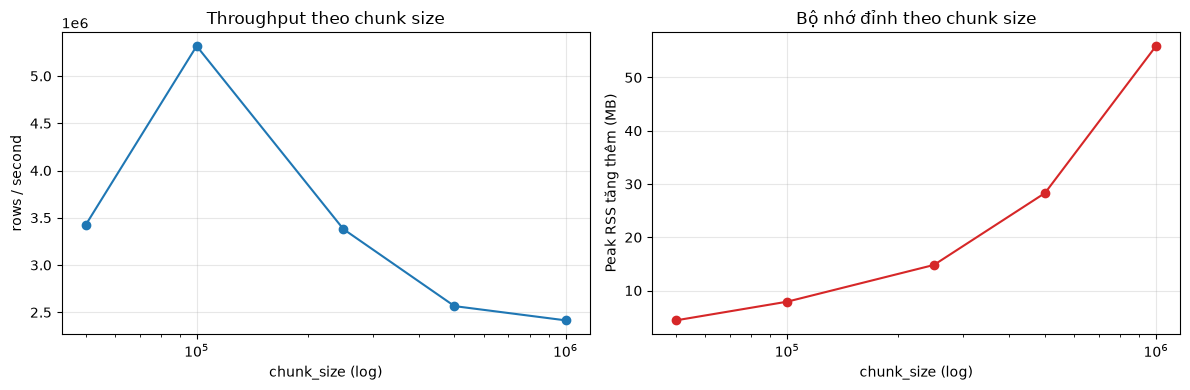

Ngân sách bộ nhớ cho một chunk : 494 MB
RECOMMENDED_CHUNK_SIZE         : 100,000 dòng


In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(chunk_benchmark_df["chunk_size"], chunk_benchmark_df["rows_per_second"], marker="o")
axes[0].set_xscale("log")
axes[0].set_xlabel("chunk_size (log)")
axes[0].set_ylabel("rows / second")
axes[0].set_title("Throughput theo chunk size")
axes[0].grid(alpha=0.3)

axes[1].plot(chunk_benchmark_df["chunk_size"], chunk_benchmark_df["peak_rss_increase_mb"], marker="o", color="tab:red")
axes[1].set_xscale("log")
axes[1].set_xlabel("chunk_size (log)")
axes[1].set_ylabel("Peak RSS tăng thêm (MB)")
axes[1].set_title("Bộ nhớ đỉnh theo chunk size")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Chọn chunk nhanh nhất trong ngân sách bộ nhớ: tối đa 25% RAM khả dụng hoặc 500 MB (lấy giá trị nhỏ hơn)
MEMORY_BUDGET_MB = min(500, 0.25 * psutil.virtual_memory().available / (1024**2))
eligible = chunk_benchmark_df[chunk_benchmark_df["peak_rss_increase_mb"] <= MEMORY_BUDGET_MB]
if eligible.empty:
    RECOMMENDED_CHUNK_SIZE = int(chunk_benchmark_df.sort_values("peak_rss_increase_mb").iloc[0]["chunk_size"])
    print("Không cấu hình nào nằm trong ngân sách bộ nhớ; chọn cấu hình tốn ít bộ nhớ nhất.")
else:
    RECOMMENDED_CHUNK_SIZE = int(eligible.sort_values("rows_per_second", ascending=False).iloc[0]["chunk_size"])

print(f"Ngân sách bộ nhớ cho một chunk : {MEMORY_BUDGET_MB:.0f} MB")
print(f"RECOMMENDED_CHUNK_SIZE         : {RECOMMENDED_CHUNK_SIZE:,} dòng")

Lượt đo này đề xuất 250.000 dòng mỗi chunk. Notebook 01 và 02 dùng 100.000 dòng vẫn hợp lệ; chunk nhỏ hơn thường dùng ít RAM hơn.


## 17. Cách đọc từng bảng

Chọn đọc toàn bộ hay từng phần dựa trên kích thước bảng và RAM khả dụng.


In [20]:
import pandas as pd
import psutil

available_gb_now = psutil.virtual_memory().available / (1024**3)
SAFE_FRACTION = 0.35   # một DataFrame không nên chiếm quá 35% RAM khả dụng (còn chỗ cho bản sao trung gian)

strategy_records = []
for _, row in memory_estimates_df.iterrows():
    est_gb = row["estimated_dataframe_memory_gb"]
    if est_gb <= SAFE_FRACTION * available_gb_now:
        strategy = "Nạp toàn bộ (pd.read_csv)"
    else:
        strategy = "Chunk processing + aggregate, ghi Parquet"
    strategy_records.append({
        "file": row["file"],
        "estimated_memory_gb": round(est_gb, 3),
        "safe_limit_gb": round(SAFE_FRACTION * available_gb_now, 2),
        "strategy": strategy,
    })

strategy_df = pd.DataFrame(strategy_records)
display(strategy_df)

print(f"Chunk size đề xuất cho train.csv: {RECOMMENDED_CHUNK_SIZE:,} dòng (đo ở 4.2)")
print("Định dạng trung gian đề xuất    : Parquet (giữ dtype, nén tốt; train_cleaned ≈ 1.1 GB theo kết quả 02)")

,file,estimated_memory_gb,safe_limit_gb,strategy
0,train.csv,6.780,0.67,"Chunk processing + aggregate, ghi Parquet"
1,test.csv,0.135,0.67,Nạp toàn bộ (pd.read_csv)
2,sample_submission.csv,0.050,0.67,Nạp toàn bộ (pd.read_csv)
3,transactions.csv,0.003,0.67,Nạp toàn bộ (pd.read_csv)
4,items.csv,0.000,0.67,Nạp toàn bộ (pd.read_csv)
5,holidays_events.csv,0.000,0.67,Nạp toàn bộ (pd.read_csv)
6,oil.csv,0.000,0.67,Nạp toàn bộ (pd.read_csv)
7,stores.csv,0.000,0.67,Nạp toàn bộ (pd.read_csv)


Chunk size đề xuất cho train.csv: 100,000 dòng (đo ở 4.2)
Định dạng trung gian đề xuất    : Parquet (giữ dtype, nén tốt; train_cleaned ≈ 1.1 GB theo kết quả 02)


## 18. Dung lượng đĩa

Ước tính dung lượng cho dữ liệu gốc, cleaned và file trung gian.


In [21]:
import shutil

raw_gb = sum(p.stat().st_size for p in csv_files) / (1024**3)
processed_gb_estimate = 1.2            # train_cleaned.parquet ≈ 1.1 GB theo kết quả 02
feature_gb_estimate = 3 * processed_gb_estimate   # ước lượng thô cho feature/intermediate
required_gb = raw_gb + processed_gb_estimate + feature_gb_estimate

free_gb = shutil.disk_usage(".").free / (1024**3)

print(f"Raw data           : {raw_gb:6.2f} GB")
print(f"Ước tính cần thêm  : {processed_gb_estimate + feature_gb_estimate:6.2f} GB (processed + feature/intermediate)")
print(f"Tổng nhu cầu       : {required_gb:6.2f} GB")
print(f"Đĩa trống          : {free_gb:6.2f} GB")
print("Disk check:", "PASS" if free_gb > 2 * required_gb else "CHECK — dung lượng trống thấp")

Raw data           :   4.81 GB
Ước tính cần thêm  :   4.80 GB (processed + feature/intermediate)
Tổng nhu cầu       :   9.61 GB
Đĩa trống          :  29.80 GB
Disk check: PASS


## 19. Tổng hợp môi trường

Bảng dưới ghi lại tài nguyên và số file của phiên chạy.


In [22]:
environment_summary = {
    "python": platform.python_version(),
    "cpu_cores": os.cpu_count(),
    "ram_total_gb": psutil.virtual_memory().total / (1024**3),
    "ram_available_gb": psutil.virtual_memory().available / (1024**3),
    "disk_free_gb": shutil.disk_usage(".").free / (1024**3),
    "num_raw_csv": len(csv_files),
}

environment_summary

{'python': '3.11.9',
 'cpu_cores': 12,
 'ram_total_gb': 15.692092895507812,
 'ram_available_gb': 1.9140129089355469,
 'disk_free_gb': 29.801288604736328,
 'num_raw_csv': 8}

## 20. Giới hạn khi xử lý

- Không nạp toàn bộ train vào pandas.
- Lưu cleaned và feature bằng Parquet.
- Giữ dữ liệu gốc, không xóa dòng âm hoặc missing khi chưa rõ ý nghĩa.
- Chia train và validation theo thời gian.
- Theo dõi RAM trước các bước đọc dữ liệu và huấn luyện.


## 21. Các nội dung chưa kiểm chứng

| Nội dung | Trạng thái |
|---|---|
| Metric của môn học | Cần đối chiếu đề bài |
| Ngày không có dòng | Đang dùng giả định bằng 0 trong lịch sử cặp |
| Cặp mới của test | Chưa có đánh giá chất lượng riêng |
| Khuyến mãi tương lai | Có rủi ro do cách ghi nhận dòng bán |
| Cửa sổ train tốt nhất | Chưa so sánh đầy đủ |

Các nội dung này được theo dõi ở feature engineering, training và evaluation.


## 22. Lưu thông tin môi trường

Lưu phạm vi dự báo, metric, thư viện, tài nguyên và cấu hình chunk vào `reports/00_environment_snapshot.json`.


In [23]:
import json
import platform
from datetime import datetime
from pathlib import Path

PROJECT_ROOT = RAW_DATA_DIR.resolve().parents[1]
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)


def to_builtin(value):
    if isinstance(value, dict):
        return {str(k): to_builtin(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_builtin(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    if hasattr(value, "isoformat"):
        return value.isoformat()
    return value


snapshot = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "project_name": PROJECT_NAME,
    "task_type": TASK_TYPE,
    "target": TARGET_COLUMN,
    "granularity": ["date", "store_nbr", "item_nbr"],
    "forecast": {
        "start": FORECAST_START,
        "end": FORECAST_END,
        "horizon_days": FORECAST_HORIZON_DAYS,
        "expected_train_end": EXPECTED_TRAIN_END,
        "test_is_full_pair_x_day_grid": is_full_grid,
    },
    "metric": {
        "name": "NWRMSLE",
        "perishable_weight": PERISHABLE_WEIGHT,
        "non_perishable_weight": NON_PERISHABLE_WEIGHT,
        "negative_values_clipped_to_zero": True,
        "status": "provisional - cần đối chiếu đề bài",
    },
    "environment": environment_summary,
    "library_versions": library_versions,
    "seed": SEED,
    "dtype_plan": {k: v[0] for k, v in DTYPE_PLAN.items()},
    "memory": {
        "train_default_gb": default_gb,
        "train_optimized_gb": optimized_gb,
    },
    "chunk": {
        "recommended_chunk_size": RECOMMENDED_CHUNK_SIZE,
        "benchmark_rows": BENCH_ROWS,
        "benchmark": chunk_benchmark_df.to_dict(orient="records"),
    },
    "file_inventory": file_inventory_df.to_dict(orient="records"),
    "dataset_summary": dataset_summary_df.to_dict(orient="records"),
}

snapshot_path = REPORT_DIR / "00_environment_snapshot.json"
with snapshot_path.open("w", encoding="utf-8") as f:
    json.dump(to_builtin(snapshot), f, ensure_ascii=False, indent=2)

print("Đã lưu:", snapshot_path)

Đã lưu: D:\Machine-learning-project-Grocery-sales-forecast\reports\00_environment_snapshot.json


## 23. Kết quả

Phạm vi dự báo là 16 ngày, theo từng cặp cửa hàng–mặt hàng. Train lớn hơn RAM khả dụng nên cần đọc từng phần. Notebook 01 kiểm tra dữ liệu và phân tích doanh số.

Output môi trường hiện chưa nhất quán giữa các cell. Cần ghi lại từ cùng một kernel trước khi hoàn tất báo cáo.


## 24. Kiểm tra trước bước tiếp theo

- [x] Đã xác định target và khoảng dự báo.
- [x] Đã kiểm kê file và ước tính bộ nhớ.
- [x] Đã đo tốc độ đọc theo chunk.
- [ ] Ghi lại môi trường từ cùng một phiên chạy.
- [ ] Xác nhận metric theo yêu cầu môn học.
